<a href="https://colab.research.google.com/github/FattahulAlim/MFattahul-PCVK_ganjil_2026/blob/main/Week7_15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Identitas Diri
Nama: Muhammad Fattahul Alim

NIM: 244107020018

Kelas: TI - 3G

Absen : 15

In [1]:
# Import library
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Text(0.5, 1.0, 'Tozero_inv')

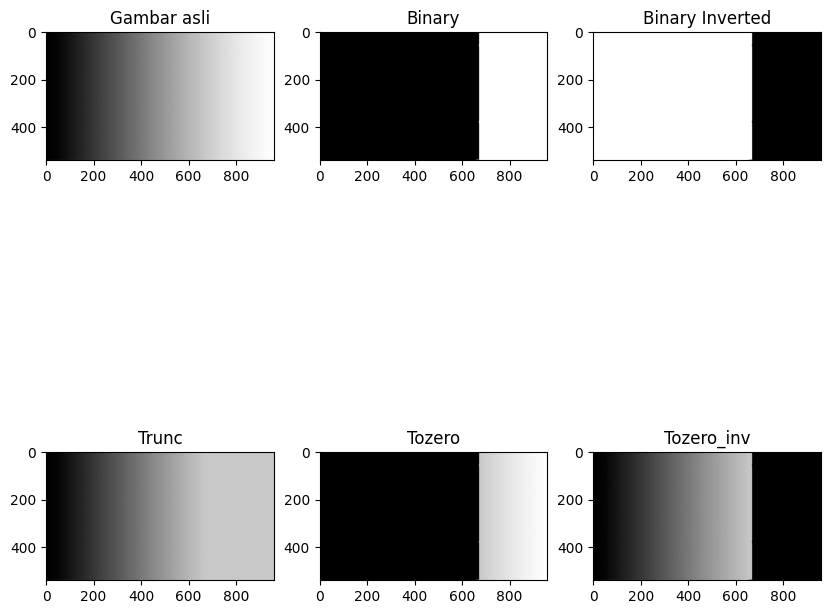

In [3]:
# Membuat gambar
img = cv.imread('/content/drive/MyDrive/PCVK-MFattahul/week-7/gradient.jpg')

tresh = 200

img_binary = np.where(img > tresh, 255, 0)
img_binary_inv = np.where(img > tresh, 0, 255)
img_trunc = np.where(img > tresh, tresh, img)
img_tozero = np.where(img > tresh, img, 0)
img_tozero_inv = np.where(img > tresh, 0, img)

plt.figure(figsize=(10, 10))
plt.subplot(2,3,1)
plt.imshow(img, cmap='gray')
plt.title('Gambar asli')
plt.subplot(2,3,2)
plt.imshow(img_binary, cmap='gray')
plt.title('Binary')
plt.subplot(2,3,3)
plt.imshow(img_binary_inv, cmap='gray')
plt.title('Binary Inverted')
plt.subplot(2,3,4)
plt.imshow(img_trunc, cmap='gray')
plt.title('Trunc')
plt.subplot(2,3,5)
plt.imshow(img_tozero, cmap='gray')
plt.title('Tozero')
plt.subplot(2,3,6)
plt.imshow(img_tozero_inv, cmap='gray')
plt.title('Tozero_inv')

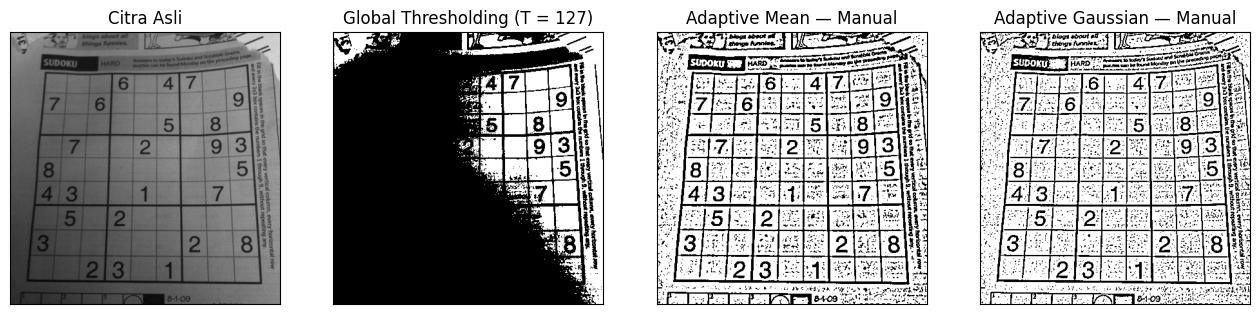

In [4]:
# Adaptive Treshold
sudoku = cv.imread('/content/drive/MyDrive/PCVK-MFattahul/week-7/sudoku-original.jpg')
sudoku_gray = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)

def global_manual(img, tresh):
  return np.where(img > tresh, 255, 0).astype(np.uint8)

def adaptive_treshold_mean(img, ksize=11, c=2):
  r = ksize // 2
  h, w = img.shape

  padded = np.pad(img.astype(np.float32), r, mode='edge')

  kernel = np.ones((ksize, ksize), np.float32) / (ksize * ksize)
  local = np.zeros((h, w), np.float32)
  for dy in range(ksize):
      for dx in range(ksize):
           local += kernel[dy, dx] * padded[dy:dy + h, dx:dx + w]

  T = local - c
  return np.where(img > T, 255, 0).astype(np.uint8)

def adaptive_treshold_gaussian(img, ksize=11, c=2, sigma=2):
  r = ksize // 2
  h, w = img.shape

  padded = np.pad(img.astype(np.float32), r, mode='edge')

  ax = np.arange(-r, r + 1)
  g = np.exp(-(ax**2) / (2 * sigma**2))
  kernel = np.outer(g, g)
  kernel = kernel / kernel.sum()

  local = np.zeros((h, w), np.float32)
  for dy in range(ksize):
    for dx in range(ksize):
      local += kernel[dy, dx] * padded[dy:dy + h, dx:dx + w]

  T = local - c
  return np.where(img > T, 255, 0).astype(np.uint8)

sudoku_global = global_manual(sudoku_gray, 127)
sudoku_mean = adaptive_treshold_mean(sudoku_gray, 11, 2)
sudoku_gaussian = adaptive_treshold_gaussian(sudoku_gray, 11, 2, 2)

titles = ['Citra Asli', 'Global Thresholding (T = 127)',
          'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
hasil = [sudoku_gray, sudoku_global, sudoku_mean, sudoku_gaussian]

plt.figure(figsize=(16, 5))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(hasil[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

95 159
85 108
95


/tmp/ipykernel_4874/565847491.py:28: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_4874/565847491.py:29: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


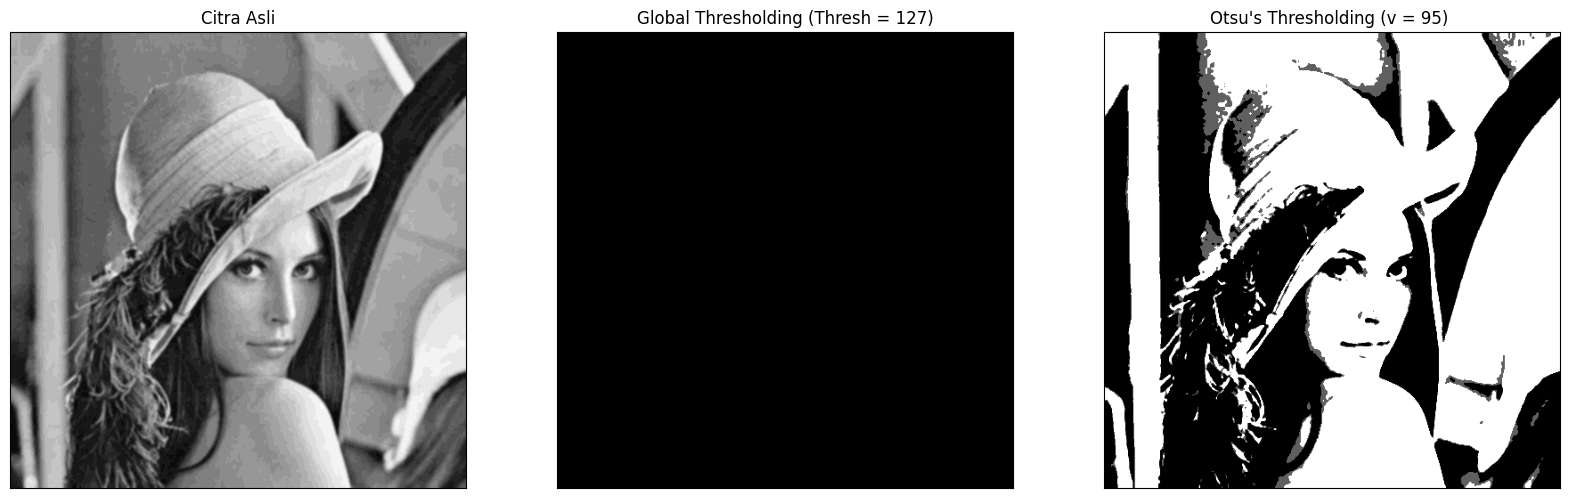

In [5]:
filename = ('/content/drive/MyDrive/PCVK-MFattahul/week-7/lena_lc.jpg')
img = cv.imread(filename, 0)
print(img.min(), img.max())

# Karena image tidak seusai dengan apa yang ada di jobsheet maka saya mengubah intensitas
# sehingga intensitas nya sesyai yaitu di antara 85-108
img = ((img.astype(np.float32) - 95) / (159 - 95) * 23 + 85).astype(np.uint8)
print(img.min(), img.max())   # sekitar 85 dan 108

blur = cv.GaussianBlur(img, (5, 5), 0)

thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+") "
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

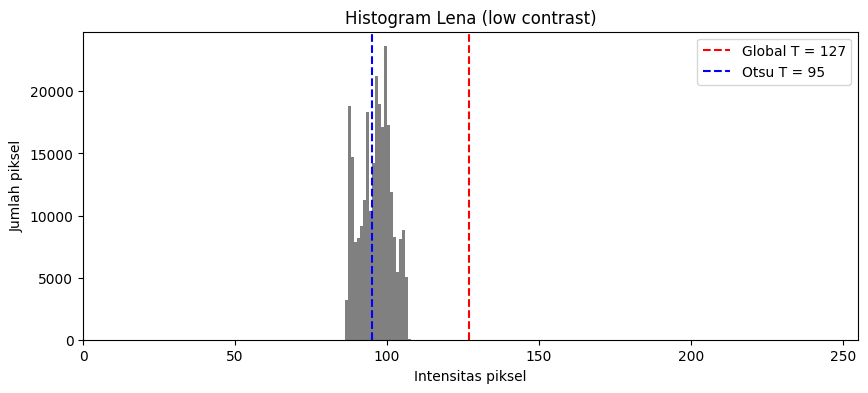

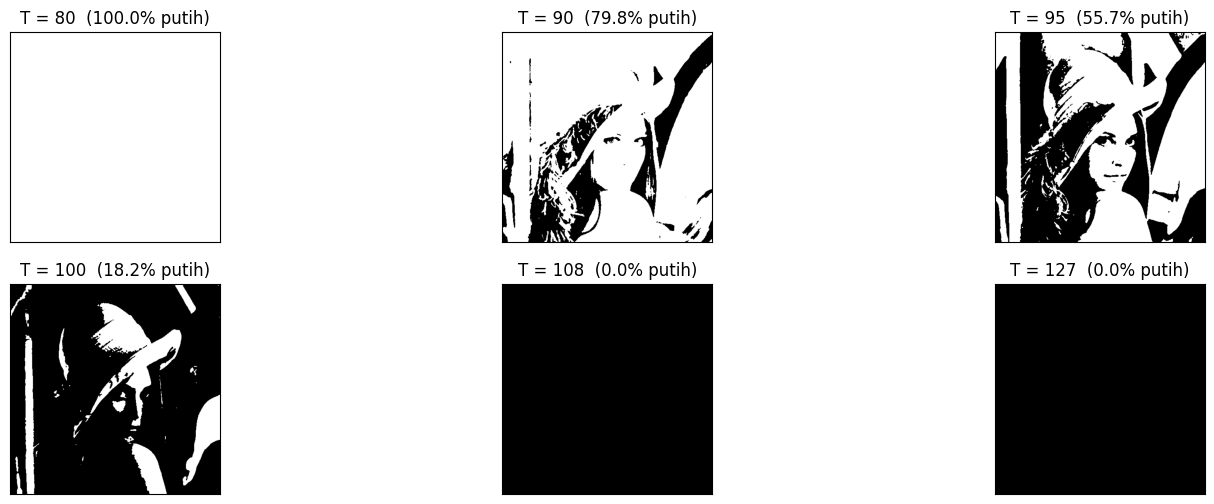

In [6]:
# Histogram + posisi threshold
plt.figure(figsize=(10, 4))
plt.hist(blur.ravel(), bins=256, range=(0, 256), color='gray')
plt.axvline(127, color='red', linestyle='--', label='Global T = 127')
plt.axvline(otsu_thresh, color='blue', linestyle='--', label=f'Otsu T = {otsu_thresh}')
plt.xlim(0, 255)
plt.xlabel('Intensitas piksel'); plt.ylabel('Jumlah piksel')
plt.title('Histogram Lena (low contrast)')
plt.legend()
plt.show()

# Coba beberapa nilai T
Tcoba = [80, 90, otsu_thresh, 100, 108, 127]
plt.figure(figsize=(18, 6))
for i, T in enumerate(Tcoba):
    hasil = np.where(blur > T, 255, 0)
    plt.subplot(2, 3, i + 1)
    plt.imshow(hasil, cmap='gray', vmin=0, vmax=255)
    plt.title(f'T = {T}  ({(hasil == 255).mean() * 100:.1f}% putih)')
    plt.xticks([]), plt.yticks([])
plt.show()

# Jawaban pertanyaan

**Mengapa Binary Threshold (T = 127) hasilnya hitam semua?**

Citra Lena yang dipakai bersifat low contrast. Dari histogram terlihat seluruh piksel hanya berkumpul di rentang sempit sekitar 85-108, sedangkan rentang penuh citra 8-bit adalah 0-255. Garis threshold T = 127 berada di sebelah kanan seluruh batang histogram. Pada Binary Threshold, piksel dengan nilai > T diubah menjadi 255 (putih) dan sisanya menjadi 0 (hitam). Karena tidak ada satu pun piksel yang bernilai > 127, semua piksel menjadi 0 sehingga citra hasil hitam seluruhnya.

**Berapa Thresh supaya Lena masih terlihat?**

Threshold harus berada di dalam rentang histogram, yaitu sekitar 85 ≤ T < 108. Dapat dilihat pada hasil percobaan T = 95 adalah yang paling baik. Nilai itu didapat dari metode Otsu, yang memilih ambang dengan memaksimalkan between-class variance. Pada histogram, garis biru (T = 95) jatuh di antara dua kelompok batang, sehingga piksel terbagi hampir seimbang menjadi objek gelap dan terang (55,7% putih, 44,3% hitam).

/tmp/ipykernel_4874/565847491.py:28: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


166


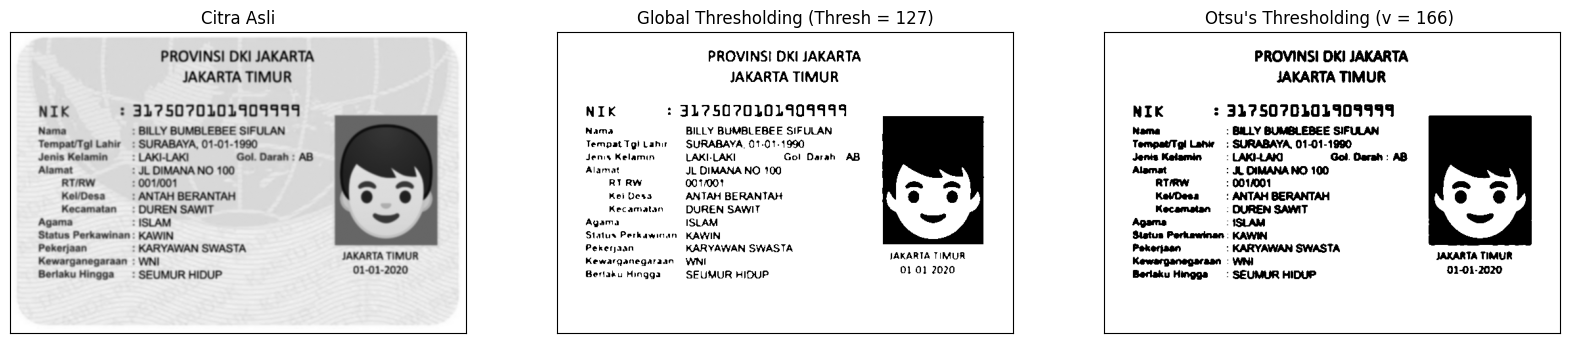

In [7]:
# Menggunakan ktp fulan
img = cv.imread('/content/drive/MyDrive/PCVK-MFattahul/week-7/ktp_fulan.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (5, 5), 0)
otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+") "
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

# Analisis

Pada citra KTP, threshold global T = 127 dan Otsu T = 166 dapat memisahkan teks dari latar karena kontras KTP cukup tinggi. Namun Otsu menentukan ambang secara otomatis dari histogram citra sehingga bernilai lebih tinggi, piksel yang bernilai 166 ke bawah akan diklasifikasikan sebagai objek berwarna hitam sehingga detail huruf dan tepiannya bisa lebih terlihat jelas dan lebih lebih tebal dibandingkan hasil dari global tresholding. Berbeda dengan citra Lena yang low contrast, di mana threshold global 127 mengubah seluruh gambar menjadi hitam (nilai piksel = 0) sedangkan Otsu berhasil menyesuaikan treshold dan membuat gambar lena tetap terlihat, pada KTP threshold global masih berhasil karena nilai 127 kebetulan berada di antara dua kelompok intensitas. Ini menunjukkan threshold global bergantung pada citra, sedangkan Otsu menyesuaikan diri secara otomatis.

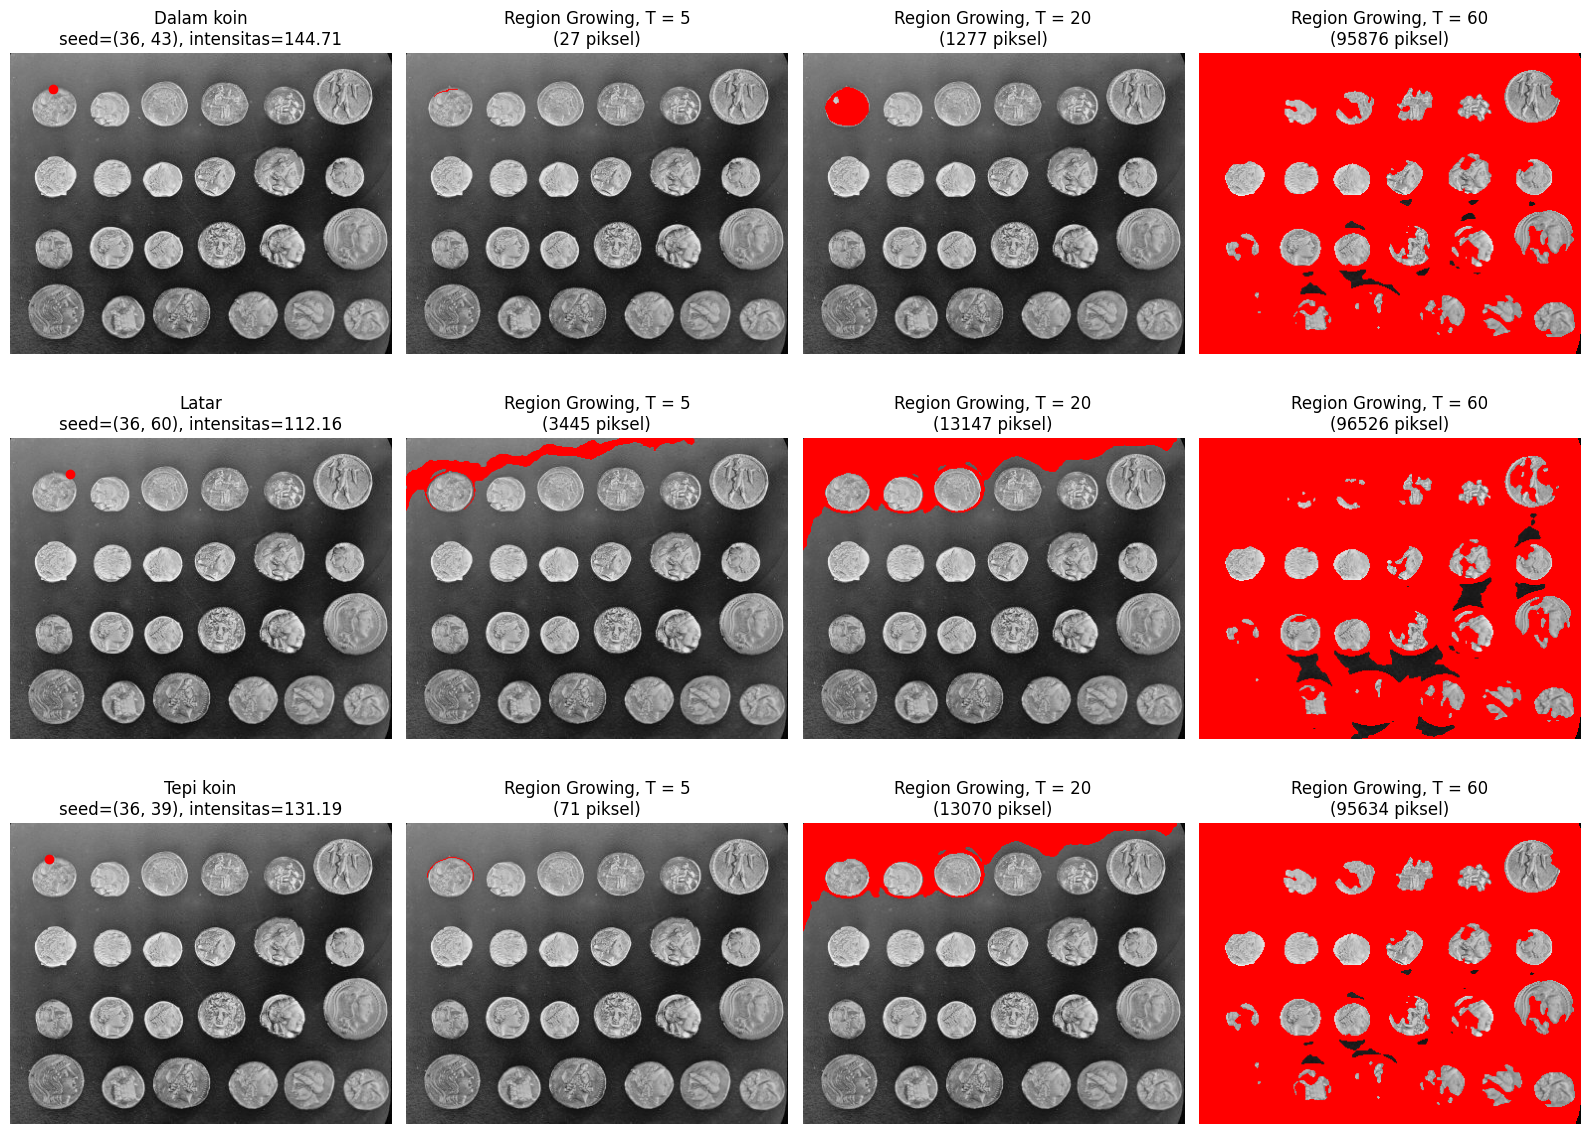

In [8]:
from skimage.filters import gaussian

img = data.coins()
smooth = gaussian(img, sigma=2, preserve_range=True)   # smoothing dulu

seeds = {
    'Dalam koin': (36, 43),
    'Latar':      (36, 60),
    'Tepi koin':  (36, 39),
}
Ts = [5, 20, 60]

def region_growing(img, seed, tresh):
    h, w = img.shape
    mask = np.zeros((h, w), dtype=bool)
    visited = np.zeros((h, w), dtype=bool)

    total = float(img[seed])      # jumlah intensitas region
    count = 1                     # banyak piksel region
    mask[seed] = True
    visited[seed] = True
    queue = deque([seed])

    while queue:
        y, x = queue.popleft()
        for dy, dx in [(-1,0),(1,0),(0,-1),(0,1),(-1,-1),(-1,1),(1,-1),(1,1)]:
            ny, nx = y + dy, x + dx
            if 0 <= ny < h and 0 <= nx < w and not visited[ny, nx]:
                mean_region = total / count
                if abs(img[ny, nx] - mean_region) <= tresh:
                    visited[ny, nx] = True
                    mask[ny, nx] = True
                    total += img[ny, nx]
                    count += 1
                    queue.append((ny, nx))
    return mask

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for r, (nama, seed) in enumerate(seeds.items()):
    ax = axes[r, 0]
    ax.imshow(img, cmap='gray')
    ax.plot(seed[1], seed[0], 'ro', markersize=6)
    ax.set_title(f'{nama}\nseed={seed}, intensitas={smooth[seed]:.2f}')
    ax.axis('off')

    for c, T in enumerate(Ts):
        mask = region_growing(smooth, seed, T)       # tumbuh di citra yang di-smooth
        overlay = np.stack([img] * 3, axis=-1).copy() # tampilkan citra asli
        overlay[mask] = [255, 0, 0]
        ax = axes[r, c + 1]
        ax.imshow(overlay)
        ax.set_title(f'Region Growing, T = {T}\n({mask.sum()} piksel)')
        ax.axis('off')

plt.tight_layout()
plt.show()

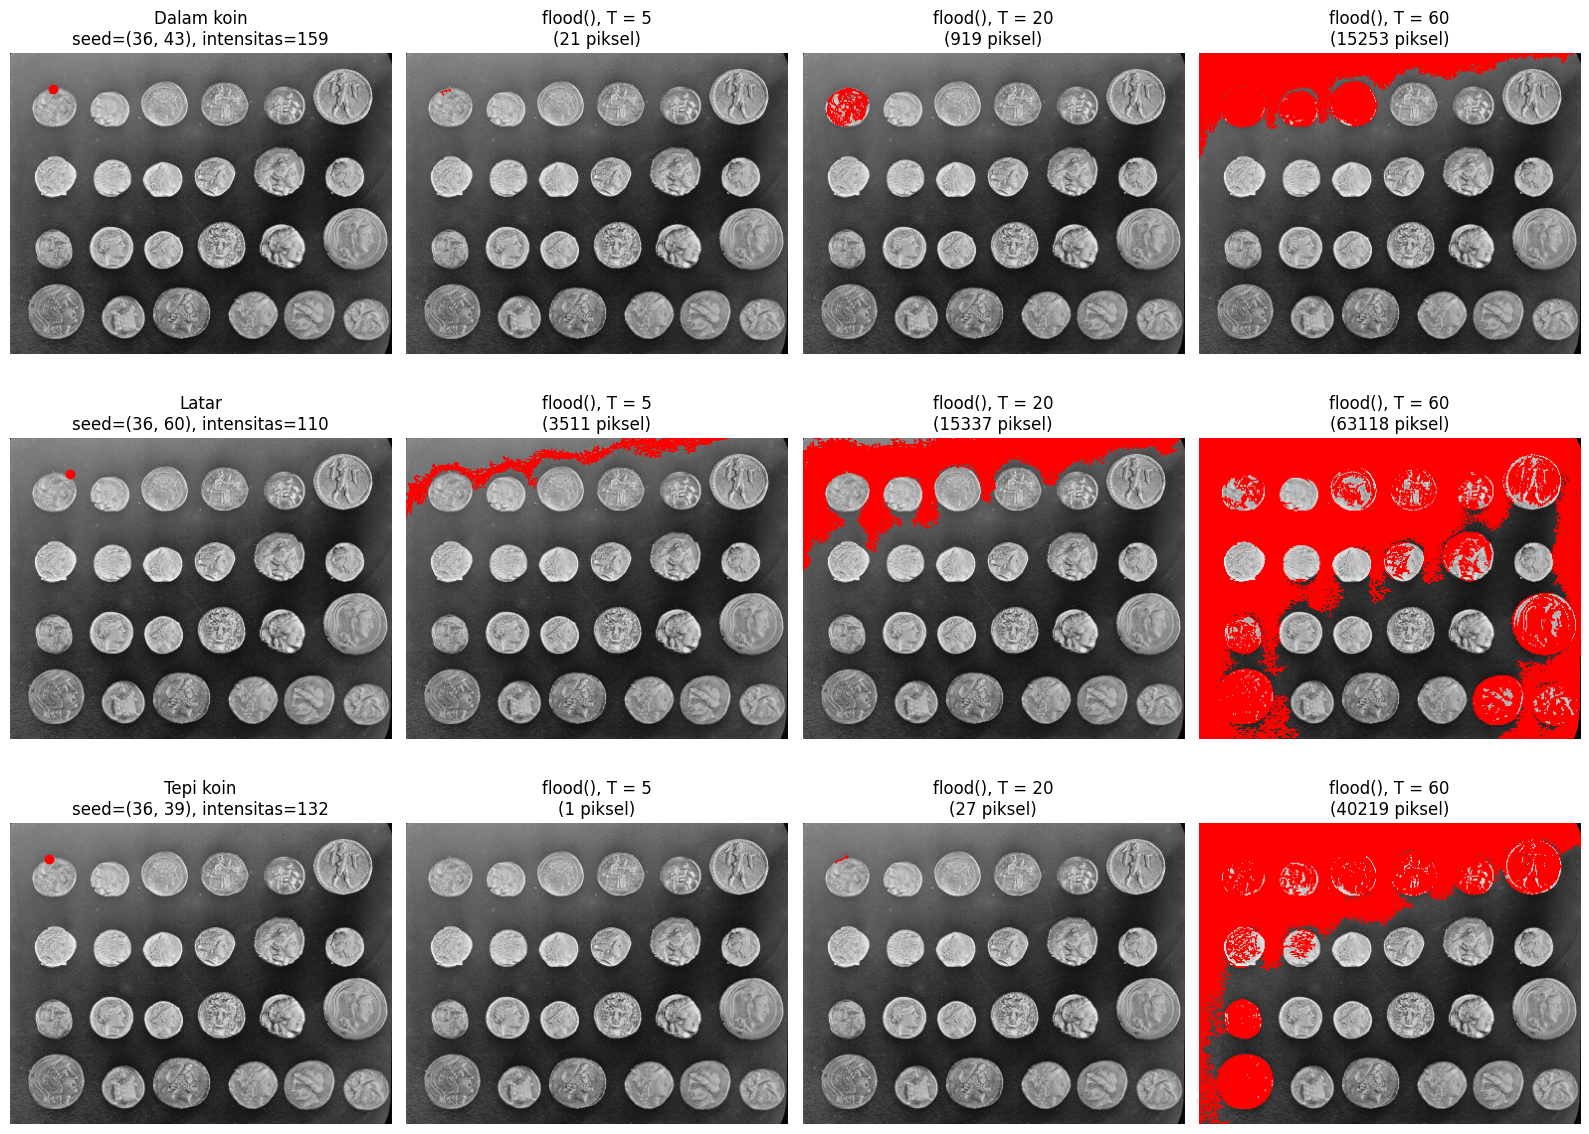

In [9]:
from skimage.segmentation import flood

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for r, (nama, seed) in enumerate(seeds.items()):
    ax = axes[r, 0]
    ax.imshow(img, cmap='gray')
    ax.plot(seed[1], seed[0], 'ro', markersize=6)
    ax.set_title(f'{nama}\nseed={seed}, intensitas={img[seed]}')
    ax.axis('off')

    for c, T in enumerate(Ts):
        mask = flood(img, seed_point=seed, tolerance=T, connectivity=1)
        overlay = np.stack([img] * 3, axis=-1).copy()
        overlay[mask] = [255, 0, 0]
        ax = axes[r, c + 1]
        ax.imshow(overlay)
        ax.set_title(f'flood(), T = {T}\n({mask.sum()} piksel)')
        ax.axis('off')

plt.tight_layout()
plt.show()

In [10]:
from sklearn.cluster import KMeans

Cluster 0: RGB=[60 61 63], HSV=(110,12,63) -> biru: False
Cluster 1: RGB=[218 238 248], HSV=(100,31,248) -> biru: True
Cluster 2: RGB=[215  70  51], HSV=(3,195,215) -> biru: False
Cluster 3: RGB=[15 16 17], HSV=(105,30,17) -> biru: False
Cluster 4: RGB=[138 149 157], HSV=(103,31,157) -> biru: True
Cluster 5: RGB=[240 211 172], HSV=(17,72,240) -> biru: False
Cluster 6: RGB=[252 254 254], HSV=(90,2,254) -> biru: False
Cluster 7: RGB=[195 224 244], HSV=(102,51,244) -> biru: True


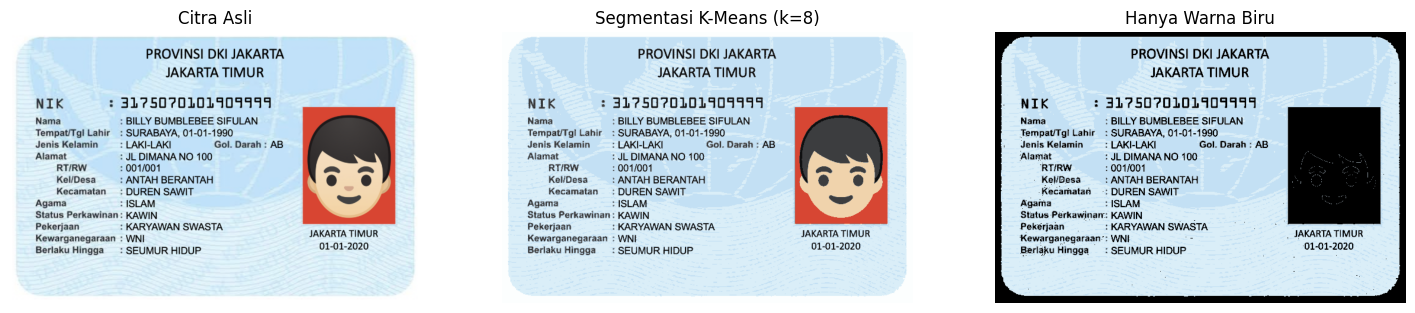

In [11]:
img = cv.imread('/content/drive/MyDrive/PCVK-MFattahul/week-7/ktp_fulan.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

k = 8
z = np.float32(img.reshape((-1, 3)))
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

segmented_img = centers[labels].reshape(img.shape)

hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
mask_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

hasil_biru = np.where(mask_biru[:, :, None], segmented_img, 0).astype(np.uint8)

centers_hsv = cv.cvtColor(centers.reshape(1, -1, 3), cv.COLOR_RGB2HSV)[0]
for i in range(k):
    h, s, v = centers_hsv[i]
    biru = (85 <= h <= 130) and (s >= 25) and (v >= 40)
    print(f'Cluster {i}: RGB={centers[i]}, HSV=({h},{s},{v}) -> biru: {biru}')

plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1); plt.imshow(img);           plt.title('Citra Asli');              plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(segmented_img); plt.title(f'Segmentasi K-Means (k={k})'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(hasil_biru);    plt.title('Hanya Warna Biru');        plt.axis('off')
plt.show()

# Tugas Kelompok

In [12]:
!apt-get update -qq
!apt-get install -y -qq tesseract-ocr tesseract-ocr-ind
!pip install -q pytesseract
!tesseract --list-langs

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...
List of available languages in "/usr/share/tesseract-ocr/5/tessdata/" (3):
eng
ind
osd


In [13]:
import pytesseract, re, difflib
from pytesseract import Output

LANG     = 'ind'
CONFIG   = '--psm 6'      # harus sama untuk semua citra dan semua KTP
CONF_MIN = 60
SKALA    = 1              # kalau tulisan kecil, coba 2
FOLDER   = '/content/drive/MyDrive/PCVK-MFattahul/week-7/'

def norm(s):                                  # abaikan besar/kecil, spasi, tanda baca
    return re.sub(r'[^0-9a-z]', '', s.lower())

def cek(target, kata):
    token = [t for t, _ in kata]
    persis = any(norm(t) == norm(target) for t in token)
    dekat = difflib.get_close_matches(norm(target), [norm(t) for t in token], n=1, cutoff=0.5)
    return persis, (dekat[0] if dekat else '(tidak terbaca)')

def gambar_kotak(im, data, conf_min=CONF_MIN):
    vis = cv.cvtColor(im, cv.COLOR_GRAY2RGB) if im.ndim == 2 else im.copy()
    n = 0
    for i, t in enumerate(data['text']):
        if t.strip() != '' and float(data['conf'][i]) > conf_min:
            x, y, w, h = data['left'][i], data['top'][i], data['width'][i], data['height'][i]
            cv.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
            n += 1
    return vis, n

def proses_ktp(nama_file, acuan, tampil=True):
    bgr = cv.imread(FOLDER + nama_file)
    assert bgr is not None, f'{nama_file} gagal dibaca, cek path/nama file!'
    if SKALA != 1:
        bgr = cv.resize(bgr, None, fx=SKALA, fy=SKALA, interpolation=cv.INTER_CUBIC)
    rgb  = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)
    gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)
    blur = cv.GaussianBlur(gray, (5, 5), 0)
    _, img_otsu = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    img_adaptive = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv.THRESH_BINARY, 31, 10)
    inputs = {'Berwarna asli': rgb, 'Segmentasi Otsu': img_otsu, 'Segmentasi Adaptive': img_adaptive}

    hasil = {}
    for nama, im in inputs.items():
        teks = pytesseract.image_to_string(im, lang=LANG, config=CONFIG)
        data = pytesseract.image_to_data(im, lang=LANG, config=CONFIG, output_type=Output.DICT)
        kata = [(t.strip(), float(c)) for t, c in zip(data['text'], data['conf'])
                if t.strip() != '' and float(c) >= 0]
        rata = np.mean([c for _, c in kata]) if kata else 0
        hasil[nama] = dict(teks=teks, data=data, kata=kata, rata=rata)

    if tampil:                                    # kotak hijau
        plt.figure(figsize=(18, 6))
        for i, nama in enumerate(inputs):
            vis, n = gambar_kotak(inputs[nama], hasil[nama]['data'])
            plt.subplot(1, 3, i + 1); plt.imshow(vis)
            plt.title(f'{nama_file} | {nama} ({n} kata, conf > {CONF_MIN})'); plt.axis('off')
        plt.show()

    baris, tepat = [], {n: 0 for n in inputs}
    for no, a in enumerate(acuan, 1):
        row = {'KTP': nama_file, 'No': no, 'Teks sebenarnya': a}
        for nama in inputs:
            ok, dekat = cek(a, hasil[nama]['kata'])
            tepat[nama] += ok
            row[nama] = f"{dekat} {'✓' if ok else '✗'}"
        baris.append(row)
    ringkas = pd.DataFrame({
        'KTP': nama_file,
        'Citra masukan OCR': list(inputs),
        'Item terbaca tepat': [tepat[n] for n in inputs],
        'Kecocokan (%)': [tepat[n] / len(acuan) * 100 for n in inputs],
        'Rata-rata confidence': [round(hasil[n]['rata'], 1) for n in inputs],
    })
    return hasil, pd.DataFrame(baris), ringkas

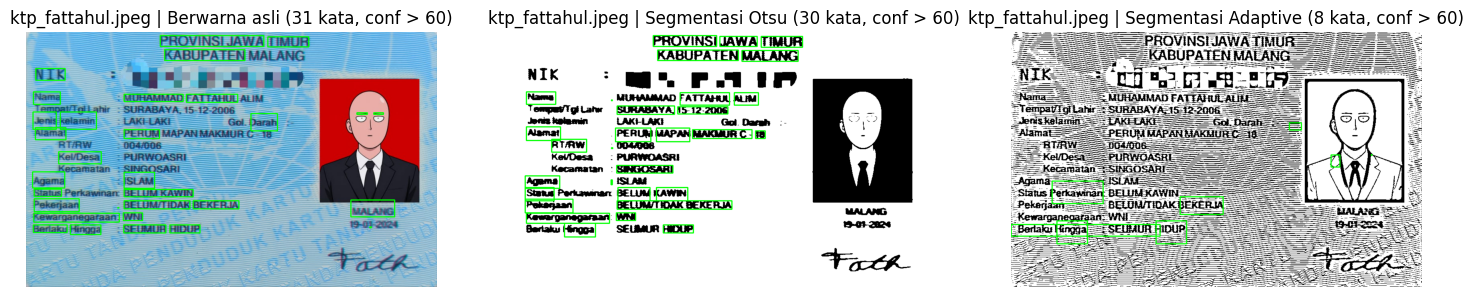

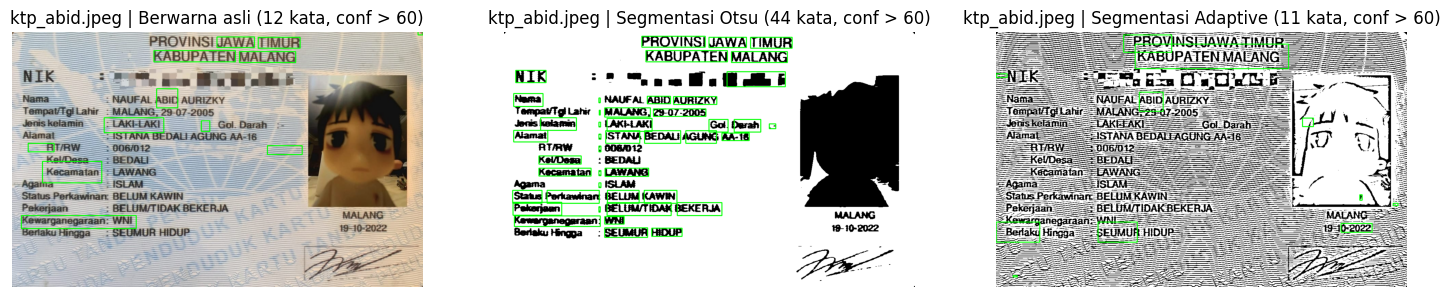

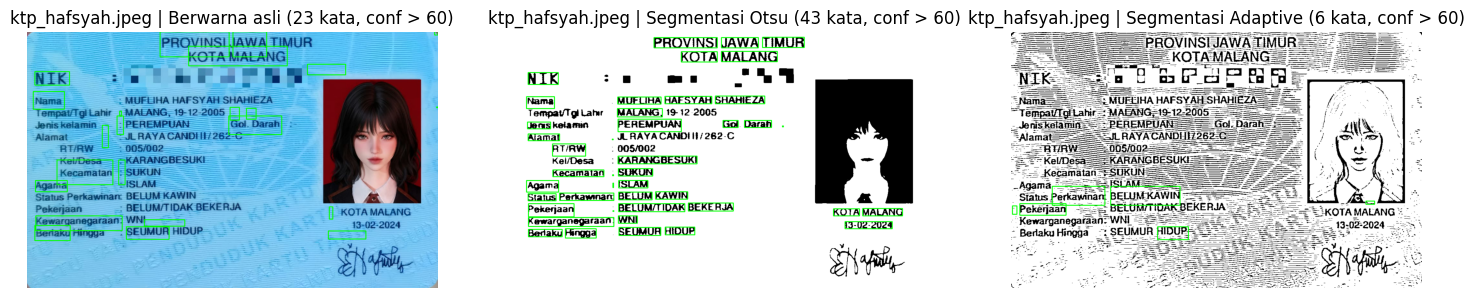

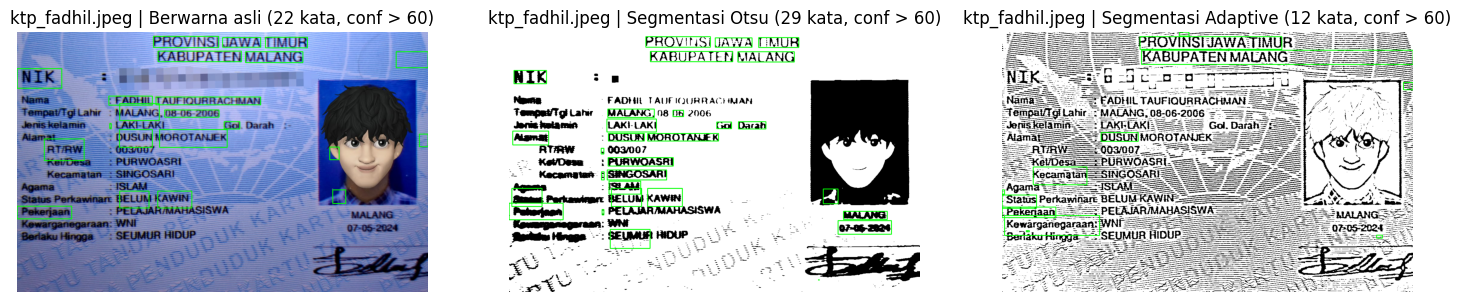

              KTP  No Teks sebenarnya     Berwarna asli    Segmentasi Otsu Segmentasi Adaptive
ktp_fattahul.jpeg   1            JAWA             raw ✗             jawa ✓                aa ✗
ktp_fattahul.jpeg   2           TIMUR           timur ✓            timur ✓             timur ✓
ktp_fattahul.jpeg   3           ISLAM           islam ✓            islam ✓                sa ✗
ktp_fattahul.jpeg   4        MUHAMMAD        muhammad ✓         muhammad ✓          muhammad ✓
ktp_fattahul.jpeg   5        FATTAHUL        fattahul ✓         fattahul ✓      fattahulalin ✗
ktp_fattahul.jpeg   6            ALIM              im ✗             alim ✓                am ✗
ktp_fattahul.jpeg   7      15-12-2006        15122006 ✓         15122006 ✓   (tidak terbaca) ✗
ktp_fattahul.jpeg   8       SINGOSARI       singosari ✓        singosari ✓         singosarp ✗
ktp_fattahul.jpeg   9             WNI             wni ✓              wni ✓               nik ✗
ktp_fattahul.jpeg  10      19-01-2024        15122

In [19]:
data_ktp = {
    'ktp_fattahul.jpeg': ['JAWA', 'TIMUR', 'ISLAM', 'MUHAMMAD', 'FATTAHUL', 'ALIM', '15-12-2006', 'SINGOSARI', 'WNI', '19-01-2024'],
    'ktp_abid.jpeg': ['JAWA', 'TIMUR', 'ISLAM', 'NAUFAL', 'ABID', 'AURIZKY', '29-07-2005', 'LAWANG', 'WNI', '19-10-2022'],
    'ktp_hafsyah.jpeg': ['JAWA', 'TIMUR', 'ISLAM', 'MUFLIHA', 'HAFSYAH', 'SHAHIEZA', '19-12-2005', 'SUKUN' 'WNI', '13-02-2024'],
    'ktp_fadhil.jpeg': ['JAWA', 'TIMUR', 'ISLAM', 'FADHIL', 'TAUFIQURRACHMAN', '08-06-2006', 'PURWOASRI', 'SINGOSARI' 'WNI', '07-05-2024']

}

semua_tabel, semua_ringkas = [], []
for nama_file, acuan in data_ktp.items():
    _, tabel, ringkas = proses_ktp(nama_file, acuan, tampil=True)   # tampil=False kalau tidak mau gambarnya
    semua_tabel.append(tabel)
    semua_ringkas.append(ringkas)

tabel_gabung   = pd.concat(semua_tabel, ignore_index=True)
ringkas_gabung = pd.concat(semua_ringkas, ignore_index=True)

print(tabel_gabung.to_string(index=False))      # tabel 10 kata, per KTP
print()
print(ringkas_gabung.to_string(index=False))    # ringkasan per KTP

rekap = (ringkas_gabung.groupby('Citra masukan OCR', sort=False)
         .agg(**{'Item tepat': ('Item terbaca tepat', 'sum'),
                 'Rata-rata kecocokan (%)': ('Kecocokan (%)', 'mean'),
                 'Rata-rata confidence': ('Rata-rata confidence', 'mean')}).round(1))
print()
print(rekap)

# Jawaban Pertanyaan Analisis

1.**Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.**

Citra masukan yang menghasilkan pembacaan paling tepat adalah citra ktp_fattahul pada metode otsu dengan kecocokan 90% dan rata rata confidence 59.8% sementara citra dengan rata rata confidence tertinggi tedapat pada ktp_hafsyah dengan nilai 74% dan kecocokan yang masih agak dibawah ktp_fattahul namun masih cukup baik yaitu 77.7%

2.**Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca**

* Kesalahan yang paling sering terjadi adalah huruf yang tidak terbaca atau salah terbacacontoh pada ktp_fattahul acuan 'jawa' dibaca 'raw' atau bahkan hanya 'aa'

* Kesalahan kedua yaitu kata yang terhubung akibat tekstur atau noise dari latar belakang ktp, ktp memiliki latar belakang yang tidak polos ada pola garis-garis halus (guilloche), tekstur, dan watermark. Karena Segmentasi Adaptive bekerja dengan mencari kontras di area lokal yang kecil, ia mengira pola latar belakang ini adalah sebuah tulisan. Akibatnya, algoritma menebalkan garis-garis latar belakang tersebut menjadi hitam pekat. Garis-garis hitam ini akhirnya menabrak dan menimpa huruf-huruf teks asli, membuat huruf tampak menyatu satu sama lain atau dipenuhi bintik hitam. Contoh kata yang terhubung sendiri ada pada citra ktp_hafsyah yang harusnya membaca 'hafsyah' dan 'shahieza' secara terpisah malah menjadi terhubung sehingga dibaca 'hafsyahshahieza'. Jika contoh huruf yang tidak terbaca ada di beberapa citra ktp dengan label (tidak terbaca)

* Kesalah ketiga adalah huruf yang tidak terbaca contohnya pada citra ktp_fattahul di metode segmentasi adaptive '15-12-2006' dan '19-01-2024' tidak terbaca

* Beberapa kesalahan juga terjadi akibat gabungan suatu masalah seperti kesalahan pembacaan huruf dan terhubungnya kata contohnya ada di ktp_fattahul yang harusnya membaca 'Alim' malah membaca 'fattahulalin' yaitu gabungan dari dua kata fattahul dan alim

3.**Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.**

Tidak selalu. Penggunaan segmentasi sangat bergantung pada algoritma yang dipilih dan kondisi citra. Segmentasi Otsu terbukti berhasil mengangkat performa akurasi di atas citra berwarna asli pada data Anda. Namun, Segmentasi Adaptive justru merusak pembacaan secara konsisten di semua file KTP, membuat tingkat kecocokan terjun bebas hingga ke angka belasan atau bahkan nol persen.

4.**Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?**

Warna atau pola latar belakang yang rumit seperti pada tekstur ktp, menciptakan variasi kontras lokal. Saat diproses dengan segmentasi yang sensitif terhadap area lokal (seperti Adaptive Threshold), pola latar belakang ini akan diterjemahkan menjadi bintik-bintik atau gumpalan hitam (noise). Noise ini kemudian menutupi batas huruf, sehingga mesin OCR tidak bisa membedakan mana teks acuan dan mana latar belakang.

5.** Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?**

Ya. Berdasarkan data tabel di atas, metode dengan confidence tertinggi memiliki kecocokan tertinggi juga. Segmentasi Otsu pada semua baris file mencatatkan nilai rata-rata confidence paling tinggi sekaligus memiliki nilai confidence yang paling tinggi. Sebaliknya, saat kecocokan terendah terjadi (Segmentasi Adaptive), nilai confidence-nya juga turun dratsis bahkan bisa mencapai 20-an%.